# P4 — Behaviour & Statistics (Harshul)

**Question:** do people whose brain connectivity looks different also have different working memory?

**Steps in this notebook**
1. Setup: load libraries and the project config
2. Make `behaviour.csv` from the HCP behavioural file
3. Merge all data into one table
4. Correlations with working memory (controlling for head motion)
5. FDR correction (because we test many metrics)
6. Motion check
7. Descriptives table
8. Scatterplots
9. Save results

> Runs on fake data (`data_synthetic`) or real data (`data`) — the switch is `data_root` in `config.yaml`.
> The same analysis also runs as one command: `python src/p4_behaviour/associations.py`.

## 1. Setup

**What we use and why**
- **pandas**: to read CSV files and join tables. It is the standard tool for tables in Python.
- **numpy**: for basic maths on arrays.
- **scipy.stats**: ready-made correlation tests (Spearman, Pearson) and FDR correction, so we don't write the statistics ourselves (less chance of mistakes).
- **matplotlib**: for the plots.
- **common/io.py**: the team's shared loader. The project rule is to load all data through it, so everyone reads the same files.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

REPO = Path("../..").resolve()          # this notebook lives in src/p4_behaviour/
sys.path.insert(0, str(REPO))
from common.io import (data_dir, load_behaviour, load_config, load_metrics,
                       load_subjects, results_dir)

cfg = load_config()
print("data_root =", cfg["data_root"])

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


data_root = data_synthetic


## 2. Make `behaviour.csv` (contract C3)

**What:** take the HCP behavioural file (downloaded from BALSA) and keep 4 columns for our subjects only.

**Working-memory score = `ListSort_Unadj`** (NIH Toolbox List Sorting test). People see pictures and must recall them in order of size.

**Why this one and not `WM_Task_2bk_Acc` (2-back accuracy in the scanner)?**
1. It is a standard, validated test.
2. It is done **outside** the scanner, so it does not depend on the fMRI session.
3. Almost every HCP subject has it (P1 also picked subjects using this column).

Set `HCP_CSV` to the downloaded file. If the file is not there yet, this step is skipped and the existing `behaviour.csv` is used.

In [2]:
HCP_CSV = Path.home() / "Downloads" / "hcp_behavioural.csv"   # ← change to the downloaded file name
WM_COLUMN = "ListSort_Unadj"

if HCP_CSV.exists():
    hcp = pd.read_csv(HCP_CSV, dtype={"Subject": str})
    our_ids = load_subjects(cfg)["subject_id"]
    beh = (hcp[["Subject", WM_COLUMN, "Age", "Gender"]]
           .rename(columns={"Subject": "subject_id", WM_COLUMN: "wm_score",
                            "Age": "age_group", "Gender": "sex"}))
    beh = beh[beh["subject_id"].isin(our_ids)].dropna(subset=["wm_score"])
    beh.to_csv(data_dir(cfg) / "behaviour.csv", index=False)
    print(f"Saved behaviour.csv for {len(beh)} of {len(our_ids)} subjects")
else:
    print("HCP file not found — using the existing behaviour.csv")

load_behaviour(cfg).head()

HCP file not found — using the existing behaviour.csv


,subject_id,wm_score,age_group,sex
0,100832,98.2,26-30,F
1,101109,101.7,22-25,M
2,102294,108.7,22-25,F
3,103624,106.9,22-25,F
4,104174,111.3,31-35,M


## 3. Merge everything into one table

**What:** join 4 files on `subject_id`, so each row = one person:
- `subjects.csv` (P1): who passed quality control + head motion (`mean_fd`)
- `behaviour.csv` (me): working-memory score
- static metrics (P2): mean FC, strength, clustering, efficiency
- dynamic metrics (P3): FC variability, transitions, time in each brain state

**Why `merge`:** it keeps only people present in all files, so no one is accidentally mismatched.

We skip metrics that are the same for everyone (e.g. `density` is fixed at 15% by design) — you can't correlate something that doesn't vary.

In [3]:
static = load_metrics("static", cfg)
dynamic = load_metrics("dynamic", cfg)

df = (load_subjects(cfg)[["subject_id", "mean_fd"]]      # included subjects only
      .merge(load_behaviour(cfg), on="subject_id")
      .merge(static, on="subject_id")
      .merge(dynamic, on="subject_id"))

metrics = [c for c in list(static.columns[1:]) + list(dynamic.columns[1:])
           if df[c].nunique() > 1]

print("People:", len(df), "| Metrics to test:", len(metrics))
df.head()

People: 11 | Metrics to test: 14


,subject_id,mean_fd,wm_score,age_group,sex,mean_fc,mean_strength,mean_clustering,global_efficiency,density,fc_variability,n_transitions,state1_frac,state1_dwell,state2_frac,state2_dwell,state3_frac,state3_dwell,state4_frac,state4_dwell
0,101109,0.082,101.7,22-25,M,0.264,23.76,0.418,0.538,0.15,0.178,13,0.411,10.4,0.193,7.6,0.180,12.9,0.216,6.4
1,102294,0.064,108.7,22-25,F,0.369,21.74,0.503,0.528,0.15,0.186,6,0.432,10.9,0.055,17.2,0.461,4.6,0.052,5.2
2,103624,0.159,106.9,22-25,F,0.239,23.09,0.462,0.482,0.15,0.206,11,0.102,14.5,0.710,7.9,0.035,3.9,0.154,15.7
3,105413,0.110,113.7,26-30,M,0.319,31.24,0.441,0.479,0.15,0.180,23,0.359,10.6,0.034,16.6,0.282,16.5,0.325,15.3
4,106349,0.132,101.1,26-30,M,0.264,19.98,0.478,0.548,0.15,0.188,22,0.245,13.8,0.114,11.0,0.125,13.4,0.516,5.0


## 4. Correlations with working memory

**Main test = partial Spearman correlation, controlling for head motion (`mean_fd`).**

- **Why Spearman, not Pearson?** Spearman works on ranks (1st, 2nd, 3rd…). With only 15 people, one extreme person can create or hide a Pearson correlation. Ranks are safer.
- **Why "partial" (remove motion)?** Our team found that head motion changes connectivity (before GSR, ρ = 0.65 between motion and mean FC). If motion also relates to memory, we could see a fake brain–memory link. Partial correlation asks: *is there a link left after removing motion?*
- **Formula:** standard partial correlation on the Spearman values; p-value uses n − 3 degrees of freedom (one extra is lost for motion).

**Extra tests:** plain Spearman and Pearson, just to compare (the project plan asks for them).

**95% confidence interval by bootstrap (5,000 times):** we resample people with replacement and recompute ρ each time. The middle 95% of those values is the CI.
*Why bootstrap?* It needs no assumption about the data's shape, and with 15 people the CI shows honestly how uncertain the result is.

In [4]:
def partial_spearman(x, y, z):
    """Spearman correlation of x and y after removing the effect of z."""
    r_xy = stats.spearmanr(x, y)[0]
    r_xz = stats.spearmanr(x, z)[0]
    r_yz = stats.spearmanr(y, z)[0]
    r = (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))
    dof = len(x) - 3
    t = r * np.sqrt(dof / (1 - r**2))
    p = 2 * stats.t.sf(abs(t), dof)
    return r, p


def bootstrap_ci(x, y, z, seed, n_boot=5000):
    """95% CI: resample people 5,000 times and recompute the partial correlation."""
    rng = np.random.default_rng(seed)
    rs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        rs.append(partial_spearman(x[i], y[i], z[i])[0])
    return np.nanpercentile(rs, [2.5, 97.5])

In [5]:
import warnings
warnings.filterwarnings("ignore")          # some bootstrap samples have ties; that's fine

wm = df["wm_score"].to_numpy(float)
fd = df["mean_fd"].to_numpy(float)
seed = cfg["dynamic"]["random_seed"]        # fixed seed → same result every run

rows = []
for m in metrics:
    x = df[m].to_numpy(float)
    r, p = partial_spearman(x, wm, fd)
    lo, hi = bootstrap_ci(x, wm, fd, seed)
    rows.append(dict(
        metric=m,
        source="static" if m in static.columns else "dynamic",
        n=len(x),
        partial_rho=r, partial_p=p, ci_low=lo, ci_high=hi,
        spearman_rho=stats.spearmanr(x, wm)[0], spearman_p=stats.spearmanr(x, wm)[1],
        pearson_r=stats.pearsonr(x, wm)[0], pearson_p=stats.pearsonr(x, wm)[1],
    ))
res = pd.DataFrame(rows)
res.round(3)

,metric,source,n,partial_rho,partial_p,ci_low,ci_high,spearman_rho,spearman_p,pearson_r,pearson_p
0,mean_fc,static,11,0.077,0.832,-0.690,0.893,-0.084,0.805,-0.175,0.607
1,mean_strength,static,11,0.748,0.013,0.109,0.963,0.733,0.010,0.665,0.026
2,mean_clustering,static,11,-0.494,0.146,-0.943,0.352,-0.469,0.145,-0.573,0.065
3,global_efficiency,static,11,-0.312,0.380,-0.871,0.581,-0.355,0.284,-0.255,0.449
4,fc_variability,dynamic,11,0.084,0.817,-0.616,0.834,0.114,0.739,0.258,0.443
5,n_transitions,dynamic,11,-0.149,0.680,-0.782,0.691,-0.150,0.659,-0.197,0.561
6,state1_frac,dynamic,11,0.279,0.435,-0.517,0.715,0.287,0.392,0.292,0.384
7,state1_dwell,dynamic,11,-0.207,0.566,-0.780,0.662,-0.009,0.979,-0.079,0.817
8,state2_frac,dynamic,11,-0.287,0.422,-0.825,0.549,-0.278,0.408,-0.331,0.320
9,state2_dwell,dynamic,11,0.239,0.507,-0.516,0.839,0.132,0.699,0.188,0.579


## 5. FDR correction

**Problem:** we test many metrics. At p < 0.05, about 1 in 20 tests looks "significant" by pure luck.

**Fix:** Benjamini–Hochberg FDR correction → gives a **q-value** for each metric. q < 0.05 means the result likely isn't just luck.

**Why FDR and not Bonferroni?** Bonferroni is very strict; with 15 people almost nothing could pass. FDR is the usual choice in brain-imaging studies.
`scipy.stats.false_discovery_control` does it in one line.

In [6]:
res["partial_q"] = stats.false_discovery_control(res["partial_p"], method="bh")
res = res.sort_values("partial_p")
print("Metrics surviving FDR (q < .05):", (res["partial_q"] < 0.05).sum(), "of", len(res))
res[["metric", "partial_rho", "ci_low", "ci_high", "partial_p", "partial_q",
     "spearman_rho", "pearson_r"]].round(3)

Metrics surviving FDR (q < .05): 0 of 14


,metric,partial_rho,ci_low,ci_high,partial_p,partial_q,spearman_rho,pearson_r
10,state3_frac,0.776,0.131,0.951,0.008,0.090,0.724,0.631
1,mean_strength,0.748,0.109,0.963,0.013,0.090,0.733,0.665
12,state4_frac,-0.675,-0.973,-0.030,0.032,0.150,-0.565,-0.542
2,mean_clustering,-0.494,-0.943,0.352,0.146,0.512,-0.469,-0.573
3,global_efficiency,-0.312,-0.871,0.581,0.380,0.797,-0.355,-0.255
8,state2_frac,-0.287,-0.825,0.549,0.422,0.797,-0.278,-0.331
6,state1_frac,0.279,-0.517,0.715,0.435,0.797,0.287,0.292
9,state2_dwell,0.239,-0.516,0.839,0.507,0.797,0.132,0.188
7,state1_dwell,-0.207,-0.780,0.662,0.566,0.797,-0.009,-0.079
13,state4_dwell,0.205,-0.580,0.809,0.569,0.797,0.169,0.109


## 6. Motion check

**Why:** if head motion itself relates to working memory or to a metric, any brain–memory link could be caused by motion. We check this directly with Spearman correlations.

In [7]:
motion = pd.DataFrame([
    dict(variable=v,
         rho_with_mean_fd=stats.spearmanr(fd, df[v])[0],
         p=stats.spearmanr(fd, df[v])[1])
    for v in ["wm_score"] + metrics
])
motion.round(3)

,variable,rho_with_mean_fd,p
0,wm_score,0.314,0.346
1,mean_fc,-0.474,0.141
2,mean_strength,0.082,0.811
3,mean_clustering,0.000,1.000
4,global_efficiency,-0.209,0.537
5,fc_variability,0.109,0.750
6,n_transitions,-0.027,0.937
7,state1_frac,0.073,0.832
8,state1_dwell,0.509,0.110
9,state2_frac,-0.018,0.958


## 7. Descriptives (Table 1 of the paper)

Who is in the sample: number of people, sex, age groups, memory score and motion.

In [8]:
desc = pd.DataFrame([
    ("N", len(df)),
    ("Female / Male", f"{(df.sex == 'F').sum()} / {(df.sex == 'M').sum()}"),
    ("Age groups", ", ".join(f"{g}: {n}" for g, n in df.age_group.value_counts().sort_index().items())),
    ("WM score mean ± SD", f"{wm.mean():.1f} ± {wm.std(ddof=1):.1f}"),
    ("Mean FD (mm) mean ± SD", f"{fd.mean():.3f} ± {fd.std(ddof=1):.3f}"),
], columns=["measure", "value"])
desc

,measure,value
0,N,11
1,Female / Male,4 / 7
2,Age groups,"22-25: 5, 26-30: 6"
3,WM score mean ± SD,108.9 ± 9.1
4,Mean FD (mm) mean ± SD,0.099 ± 0.046


## 8. Scatterplots

One small plot per metric: each dot = one person. The red line is a straight-line fit, only to guide the eye; the number in the title is the main test (partial ρ).
**Why scatterplots?** With 15 people you must *see* the data — one outlier can make a correlation look strong.

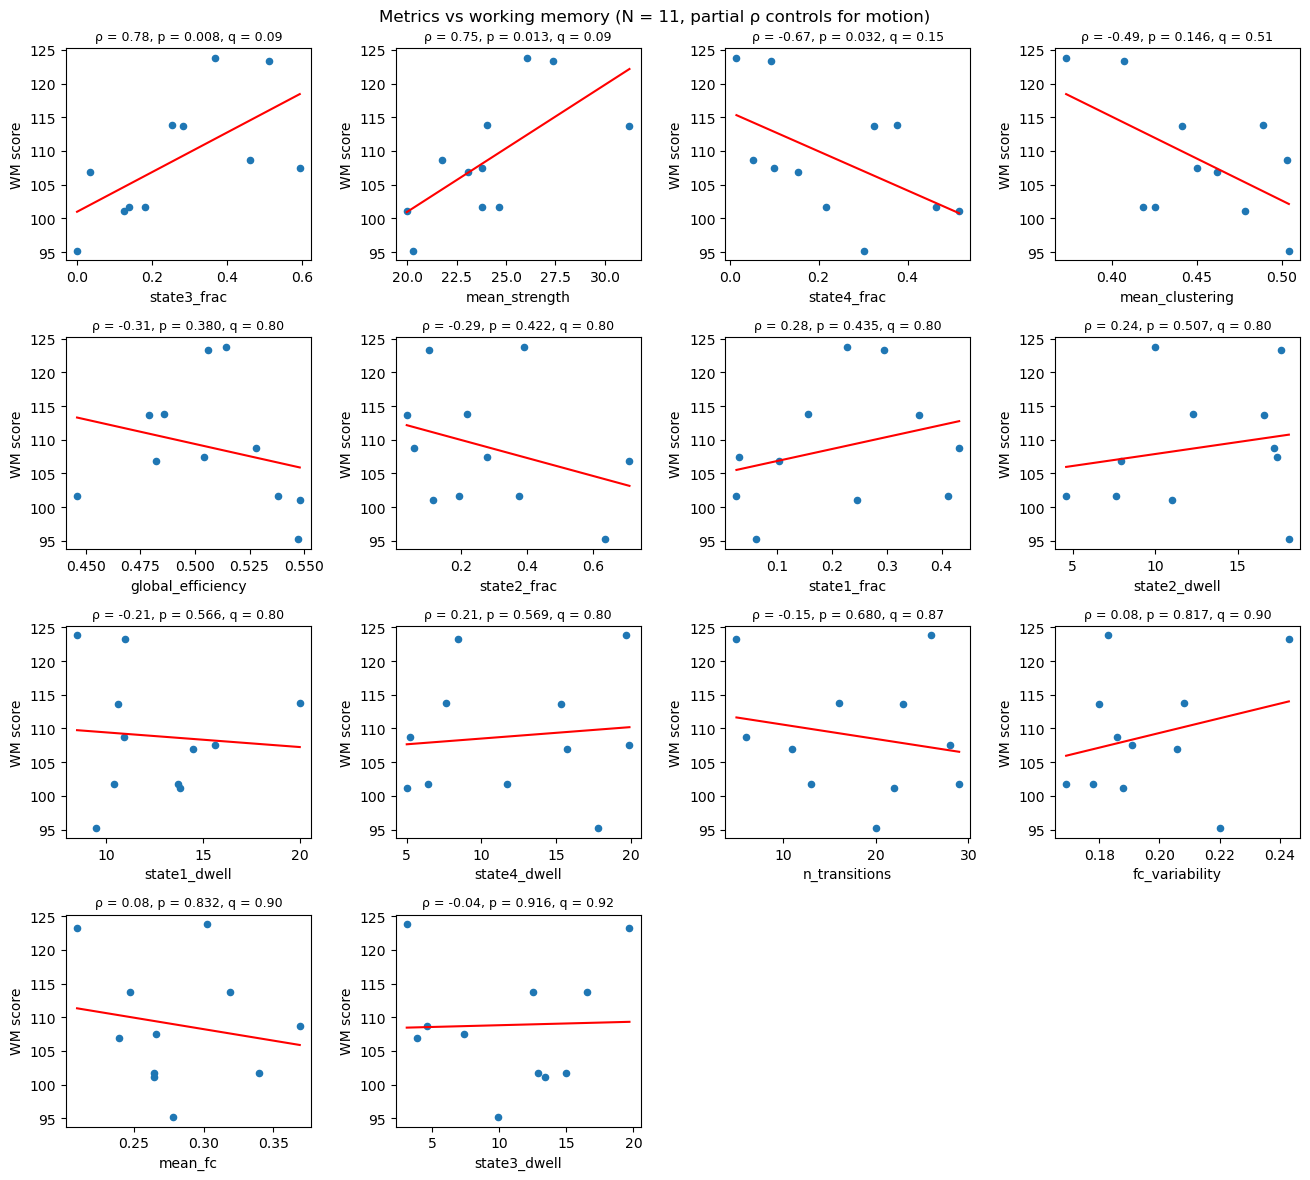

In [9]:
ncol = 4
nrow = int(np.ceil(len(res) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3 * nrow), squeeze=False)
for ax, row in zip(axes.flat, res.itertuples()):
    x = df[row.metric]
    ax.scatter(x, wm, s=20)
    slope, intercept = np.polyfit(x, wm, 1)
    ax.plot(np.sort(x), intercept + slope * np.sort(x), color="red")
    ax.set_xlabel(row.metric)
    ax.set_ylabel("WM score")
    ax.set_title(f"ρ = {row.partial_rho:.2f}, p = {row.partial_p:.3f}, q = {row.partial_q:.2f}", fontsize=9)
for ax in axes.flat[len(res):]:
    ax.axis("off")
fig.suptitle(f"Metrics vs working memory (N = {len(df)}, partial ρ controls for motion)")
fig.tight_layout()
plt.show()

## 9. Save results

Files go to `results/stats/` (real data) or `results_synthetic/stats/` (fake data) — `results_dir()` picks the right one.

In [10]:
out = results_dir(cfg) / "stats"
(out / "figures").mkdir(parents=True, exist_ok=True)
res.round(4).to_csv(out / "associations.csv", index=False)
motion.round(4).to_csv(out / "motion_check.csv", index=False)
desc.to_csv(out / "descriptives.csv", index=False)
fig.savefig(out / "figures" / "scatter_grid.png", dpi=150)
print("Saved to", out)

Saved to /Users/harshul/fmri-dfc-pilot/results_synthetic/stats


## How to read the results (for the paper)

- Report **partial ρ with its 95% CI**, plus p and q.
- With 15 people, only |ρ| above about 0.5 can reach p < 0.05, and CIs are wide.
- Write **"exploratory association"**, never "predicts". If nothing survives FDR, that is expected at N = 15 and does **not** prove there is no effect.